# How a gprMax file becomes one scan

gprMax writes each run as an HDF5 file, with extension `.h5` or the older `.out`. This notebook reads that file into one scan:

- `data`, shape `(samples, traces)`, one column per trace
- `dt`, the sample interval in seconds
- `positions`, the receiver coordinate of each trace, in metres, shape `(traces, 3)`
- `trace_spacing`, the step between those coordinates, in metres
- `frequency`, the source centre frequency in hertz
- `source`, the transmitter: name, kind, polarisation, waveform, amplitude, and where it stood

Two files already in the repository are used throughout. The cylinder file is one A-scan, so the waveform is still stored. The pipe file is a merged B-scan of 60 traces, and the merge drops the waveform.


## Setup

`ASCAN` and `BSCAN` are the two outputs. `as_text` and `as_float` turn HDF5 attribute values into a plain string or a float. A missing attribute stays `None`.


In [1]:
from pathlib import Path
import re
import tempfile

import h5py
import matplotlib.pyplot as plt
import numpy as np

def repo_root():
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "data" / "sim" / "cylinder_Ascan_2D.h5").is_file():
            return candidate
    raise FileNotFoundError("open this notebook from the GPRadar repository")

ROOT = repo_root()
ASCAN = ROOT / "data" / "sim" / "cylinder_Ascan_2D.h5"
BSCAN = ROOT / "data" / "sim" / "pipe_study" / "f1.5_e6_s0_d5" / "pipe_merged.h5"
SUFFIXES = {".h5", ".out"}

def as_text(value):
    if value is None:
        return None
    if isinstance(value, bytes):
        value = value.decode()
    elif isinstance(value, np.ndarray):
        value = value.item() if value.shape == () else value
        if isinstance(value, bytes):
            value = value.decode()
    text = str(value)
    return text or None

def as_float(value):
    if value is None:
        return None
    number = float(np.asarray(value))
    if not np.isfinite(number):
        return None
    return number

def natural_key(value):
    text = value.name if isinstance(value, Path) else str(value)
    return [int(part) if part.isdigit() else part.lower() for part in re.split(r"(\d+)", text)]

%matplotlib inline


## 1. Which files count

A scan can come from one file, from a directory of per-trace files, or from an explicit list of paths.

In a directory, only `.h5` and `.out` files count. A name that contains `_merged` is skipped when individual traces are also present, so the merged copy is not stacked on top of the traces. The remaining names are sorted so that `pipe2` comes before `pipe10`. Alphabetical order would put `pipe10` first.


In [2]:
def collect_files(source):
    if isinstance(source, (str, Path)):
        path = Path(source)
        if path.is_dir():
            files = [
                item for item in path.iterdir()
                if item.is_file() and item.suffix.lower() in SUFFIXES and not item.name.startswith(".")
            ]
            traces = [item for item in files if "_merged" not in item.stem]
            files = traces or files
            if not files:
                raise FileNotFoundError(f"no gprMax output files in {path}")
            return tuple(sorted(files, key=natural_key))
        if not path.is_file():
            raise FileNotFoundError(path)
        return (path,)

    files = tuple(Path(item) for item in source)
    if not files:
        raise ValueError("no gprMax output files were given")
    missing = [str(path) for path in files if not path.is_file()]
    if missing:
        raise FileNotFoundError("gprMax output file(s) not found: " + ", ".join(missing))
    return files

print("one file:", [path.name for path in collect_files(BSCAN)])


one file: ['pipe_merged.h5']


## 2. Two layouts

An A-scan stores the source under `srcs/src1`, including an `excitation` group that names the waveform. A merged B-scan keeps one `rxs/rx1` dataset with a column per trace, and moves the per-trace coordinates to `trace_metadata`. The `srcs` group itself is gone.


In [3]:
def groups(path):
    with h5py.File(path, "r") as output:
        names = []
        def visit(name, item):
            if isinstance(item, h5py.Group):
                names.append(name)
        output.visititems(visit)
        return names

print("A-scan groups:")
for name in groups(ASCAN):
    print(" ", name)
print("merged B-scan groups:")
for name in groups(BSCAN):
    print(" ", name)


A-scan groups:
  rxs
  rxs/rx1
  srcs
  srcs/src1
  srcs/src1/excitation
merged B-scan groups:
  rxs
  rxs/rx1
  trace_metadata
  trace_metadata/rxs
  trace_metadata/rxs/rx1
  trace_metadata/srcs
  trace_metadata/srcs/src1


## 3. The field

The receiver group is `rxs/rx1` unless another name is given. The dataset read here is `Ez`. A single trace is stored as a 1D array; an extra axis makes every scan shape `(samples, traces)`. A merged file is already 2D.


In [4]:
def read_field(path, component="Ez", receiver="rx1"):
    with h5py.File(path, "r") as output:
        rxs = output.get("rxs")
        if rxs is None or receiver not in rxs:
            found = [] if rxs is None else list(rxs.keys())
            names = ", ".join(found) if found else "none"
            raise KeyError(f"{path.name} has no receiver {receiver!r} (found {names})")
        group = rxs[receiver]
        if component not in group or not isinstance(group[component], h5py.Dataset):
            available = [name for name, item in group.items() if isinstance(item, h5py.Dataset)]
            names = ", ".join(available) if available else "none"
            raise KeyError(f"{path.name} receiver has no {component} dataset (found {names})")
        data = np.asarray(group[component], dtype=float)
    if data.ndim == 1:
        data = data[:, np.newaxis]
    if data.ndim != 2 or data.shape[0] < 1 or data.shape[1] < 1:
        raise ValueError(f"{path.name} {component} must be a non-empty trace or a time-by-trace array")
    return data

ascan_field = read_field(ASCAN)
bscan_field = read_field(BSCAN)
print("A-scan", ascan_field.shape, ascan_field.dtype)
print("B-scan", bscan_field.shape, bscan_field.dtype)


A-scan (637, 1) float64
B-scan (1061, 60) float64


## 4. The sample interval

`dt` is a root attribute, in seconds. It has to be finite and positive. Both of these runs use the same mesh, so they share `dt`. The pipe record is longer because its time window is 5 ns rather than 3 ns.


In [5]:
def read_dt(path):
    try:
        output = h5py.File(path, "r")
    except OSError as exc:
        raise ValueError(f"{path.name} is not a gprMax HDF5 output") from exc
    with output:
        if "dt" not in output.attrs:
            raise ValueError(f"{path.name} has no dt attribute")
        dt = float(output.attrs["dt"])
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError(f"{path.name} has an invalid dt")
    return dt

dt_ascan = read_dt(ASCAN)
dt_bscan = read_dt(BSCAN)
print(f"A-scan dt = {dt_ascan * 1e12:.3f} ps, record = {ascan_field.shape[0] * dt_ascan * 1e9:.2f} ns")
print(f"B-scan dt = {dt_bscan * 1e12:.3f} ps, record = {bscan_field.shape[0] * dt_bscan * 1e9:.2f} ns")


A-scan dt = 4.717 ps, record = 3.00 ns
B-scan dt = 4.717 ps, record = 5.01 ns


## 5. Where the receiver was

A merged file stores one coordinate per trace in `trace_metadata/rxs/rx1/Position`, shape `(traces, 3)`. That table is used when it is present and has one row per trace.

A file that was not merged stores only the first receiver position, as an attribute of `rxs/rx1`, plus `rxsteps` counted in cells. The step in metres is `dx_dy_dz * rxsteps`. Trace `i` is `origin + i * step`. On the A-scan that step is zero, so the one receiver stays where it was placed.


In [6]:
def cell_step(output, attribute):
    dx = np.asarray(output.attrs.get("dx_dy_dz", [0.0, 0.0, 0.0]), dtype=float)
    steps = np.asarray(output.attrs.get(attribute, [0, 0, 0]), dtype=float)
    return dx * steps

def receiver_positions(path, n_traces, receiver="rx1"):
    with h5py.File(path, "r") as output:
        recorded = output.get(f"trace_metadata/rxs/{receiver}/Position")
        if isinstance(recorded, h5py.Dataset):
            positions = np.asarray(recorded, dtype=float)
            if positions.shape == (n_traces, 3):
                return positions
        origin = np.asarray(output[f"rxs/{receiver}"].attrs["Position"], dtype=float)
        return origin + np.arange(n_traces, dtype=float)[:, np.newaxis] * cell_step(output, "rxsteps")

print("A-scan receiver", receiver_positions(ASCAN, ascan_field.shape[1]))
rx = receiver_positions(BSCAN, bscan_field.shape[1])
print("B-scan receiver, first", rx[0], "last", rx[-1], "shape", rx.shape)


A-scan receiver [[0.14 0.17 0.  ]]
B-scan receiver, first [0.08 0.17 0.  ] last [0.198 0.17  0.   ] shape (60, 3)


## 6. Trace spacing

The spacing is the distance between successive receiver positions. One trace has no spacing, so the result is `None`. The same is true when a coordinate is missing. Steps that are zero, or that are not all equal, are refused rather than reported as one number.


In [7]:
def trace_spacing(positions):
    if positions.shape[0] < 2 or not np.all(np.isfinite(positions)):
        return None
    distances = np.linalg.norm(np.diff(positions, axis=0), axis=1)
    if distances.size == 0 or np.any(distances <= 0) or not np.isfinite(distances).all():
        return None
    spacing = float(np.median(distances))
    if not np.allclose(distances, spacing, rtol=1e-4, atol=1e-6):
        raise ValueError("trace positions are not equally spaced")
    return spacing

print("A-scan spacing", trace_spacing(receiver_positions(ASCAN, ascan_field.shape[1])))
print(f"B-scan spacing {trace_spacing(rx) * 1e3:.1f} mm")


A-scan spacing None
B-scan spacing 2.0 mm


## 7. The source

The first source name, in natural order, is the transmitter for the scan.

On the A-scan, `srcs/src1/excitation` holds the waveform. The kind and polarisation are taken from that group, and fall back to the attributes on `srcs/src1` itself. The frequency is `WaveformFrequency`, in hertz.

On the merged B-scan the `srcs` group is gone. The name and the per-trace positions survive under `trace_metadata/srcs/src1`. There is no excitation left, so the kind, the waveform, and the frequency are `None`.

Positions follow the same rule as the receiver. A merged file uses the stored table. A single file uses the source `Position` attribute plus `srcsteps` times the cell size. If neither is present, the coordinates are left as missing values.


In [8]:
def source_name(output):
    sources = output.get("srcs")
    if sources is not None and len(sources):
        names = sorted(sources.keys(), key=natural_key)
        return sources[names[0]], names[0]
    recorded = output.get("trace_metadata/srcs")
    if recorded is not None and len(recorded):
        names = sorted(recorded.keys(), key=natural_key)
        return None, names[0]
    return None, None

def source_positions(output, name, n_traces):
    if name is not None:
        recorded = output.get(f"trace_metadata/srcs/{name}/Position")
        if isinstance(recorded, h5py.Dataset):
            positions = np.asarray(recorded, dtype=float)
            if positions.shape == (n_traces, 3):
                return positions
    origin = None
    if name is not None and name in output.get("srcs", {}):
        if "Position" in output["srcs"][name].attrs:
            origin = np.asarray(output["srcs"][name].attrs["Position"], dtype=float)
    if origin is None:
        return np.full((n_traces, 3), np.nan)
    return origin + np.arange(n_traces, dtype=float)[:, np.newaxis] * cell_step(output, "srcsteps")

def attr(attrs, name, fallback=None):
    if name in attrs:
        return attrs[name]
    return fallback

def read_source(path, n_traces):
    with h5py.File(path, "r") as output:
        group, name = source_name(output)
        excitation = group.get("excitation") if group is not None else None
        attrs = excitation.attrs if isinstance(excitation, h5py.Group) else {}
        group_attrs = group.attrs if group is not None else {}
        # Copy the values out before the file closes. An attribute object
        # does not survive the with-block.
        kind = as_text(attr(attrs, "SourceType", attr(group_attrs, "Type")))
        polarisation = as_text(attr(attrs, "Polarisation", attr(group_attrs, "Polarisation")))
        waveform_id = as_text(attr(attrs, "WaveformID", attr(group_attrs, "Waveform")))
        waveform_type = as_text(attr(attrs, "WaveformType"))
        amplitude = as_float(attr(attrs, "WaveformAmplitude"))
        frequency = as_float(attr(attrs, "WaveformFrequency"))
        positions = source_positions(output, name, n_traces)
    return {
        "name": name or "",
        "kind": kind,
        "polarisation": polarisation,
        "waveform_id": waveform_id,
        "waveform_type": waveform_type,
        "amplitude": amplitude,
        "frequency": frequency,
        "position": positions[0].copy(),
        "positions": positions,
    }

print("A-scan source")
ascan_source = read_source(ASCAN, ascan_field.shape[1])
for key, value in ascan_source.items():
    if key != "positions":
        print(f"  {key}: {value}")
print("B-scan source")
bscan_source = read_source(BSCAN, bscan_field.shape[1])
for key, value in bscan_source.items():
    if key != "positions":
        print(f"  {key}: {value}")
print("B-scan source x, first and second", bscan_source["positions"][:2, 0])


A-scan source
  name: src1
  kind: HertzianDipole
  polarisation: z
  waveform_id: my_ricker
  waveform_type: ricker
  amplitude: 1.0
  frequency: 1500000000.0
  position: [0.1  0.17 0.  ]
B-scan source
  name: src1
  kind: None
  polarisation: None
  waveform_id: None
  waveform_type: None
  amplitude: None
  frequency: None
  position: [0.04 0.17 0.  ]
B-scan source x, first and second [0.04  0.042]


## 8. One file becomes one scan

The pieces above belong together: the field, `dt`, the receiver positions, the spacing, the frequency, and the source. `frequency` is the source centre frequency, which is `None` when the merge has dropped the waveform.


In [9]:
def read_scan(path, component="Ez", receiver="rx1"):
    data = read_field(path, component, receiver)
    positions = receiver_positions(path, data.shape[1], receiver)
    source = read_source(path, data.shape[1])
    return {
        "data": data,
        "dt": read_dt(path),
        "positions": positions,
        "trace_spacing": trace_spacing(positions),
        "frequency": source["frequency"],
        "source": source,
        "component": component,
    }

ascan_scan = read_scan(ASCAN)
bscan_scan = read_scan(BSCAN)
for label, scan in (("A-scan", ascan_scan), ("B-scan", bscan_scan)):
    spacing = scan["trace_spacing"]
    print(
        label,
        scan["data"].shape,
        f"dt={scan['dt'] * 1e12:.3f} ps",
        "spacing=" + ("None" if spacing is None else f"{spacing * 1e3:.1f} mm"),
        f"frequency={scan['frequency']}",
        f"source={scan['source']['kind']}",
    )


A-scan (637, 1) dt=4.717 ps spacing=None frequency=1500000000.0 source=HertzianDipole
B-scan (1061, 60) dt=4.717 ps spacing=2.0 mm frequency=None source=None


## 9. The two pictures

The A-scan is one trace of Ez against time. The B-scan uses the receiver x coordinate across the page, and time increases downward. Red is positive Ez and blue is negative. The colour scale stops at the 99th percentile of the absolute amplitude.


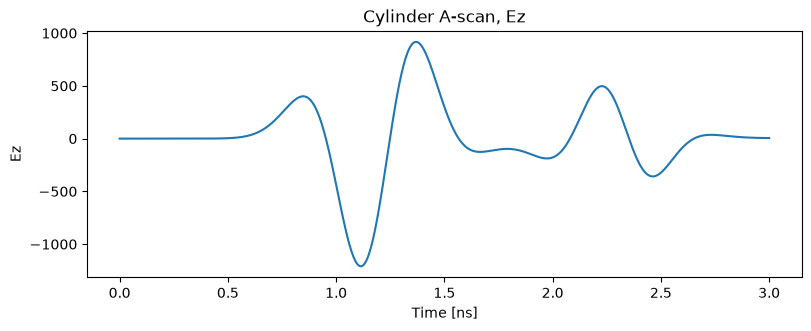

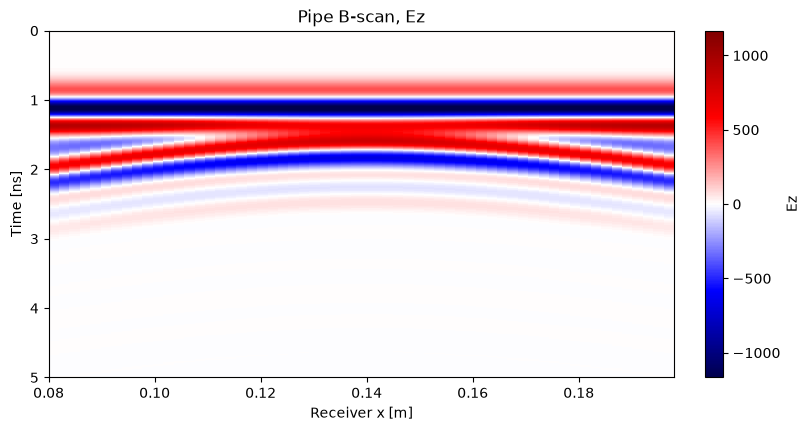

In [10]:
def show_ascan(scan, title):
    values = scan["data"][:, 0]
    time_ns = np.arange(values.size) * scan["dt"] * 1e9
    fig, ax = plt.subplots(figsize=(8, 3.2), constrained_layout=True)
    ax.plot(time_ns, values)
    ax.set_title(title)
    ax.set_xlabel("Time [ns]")
    ax.set_ylabel("Ez")
    plt.show()

def show_bscan(scan, title):
    values = scan["data"]
    time_ns = np.arange(values.shape[0]) * scan["dt"] * 1e9
    position = scan["positions"][:, 0]
    limit = float(np.percentile(np.abs(values), 99)) or 1.0
    fig, ax = plt.subplots(figsize=(8, 4.2), constrained_layout=True)
    image = ax.imshow(
        values,
        extent=[position[0], position[-1], time_ns[-1], time_ns[0]],
        aspect="auto",
        cmap="seismic",
        vmin=-limit,
        vmax=limit,
        interpolation="nearest",
    )
    fig.colorbar(image, ax=ax, label="Ez")
    ax.set_title(title)
    ax.set_xlabel("Receiver x [m]")
    ax.set_ylabel("Time [ns]")
    plt.show()

show_ascan(ascan_scan, "Cylinder A-scan, Ez")
show_bscan(bscan_scan, "Pipe B-scan, Ez")


## 10. Several single-trace files

gprMax can leave one file per antenna position (`pipe1.h5`, `pipe2.h5`, …) instead of a merged file. A directory, or a list of those paths, is read one file at a time and the columns are placed side by side.

Each file must contain exactly one trace. The traces must share the number of samples, `dt`, and the source frequency. The source description is taken from the first file. Its positions, and the receiver positions, are stacked in the same order as the columns. The spacing is computed again from the stacked receiver coordinates. Because each per-trace file still holds the excitation, the stacked scan keeps the frequency.

The pipe study in this repository has already been merged. The four files below are written only to show the directory rule: `pipe10` sorts after `pipe2`, and `pipe_merged` is left out.


In [11]:
def stack_scans(paths, component="Ez", receiver="rx1"):
    scans = [read_scan(path, component, receiver) for path in paths]
    widths = [scan["data"].shape[1] for scan in scans]
    if any(width != 1 for width in widths):
        raise ValueError("stack single-trace outputs, or pass one merged file")
    if len({scan["data"].shape[0] for scan in scans}) != 1:
        raise ValueError("trace files do not have the same number of samples")
    if len({scan["dt"] for scan in scans}) != 1:
        raise ValueError("trace files do not have the same dt")
    if len({scan["frequency"] for scan in scans}) != 1:
        raise ValueError("trace files do not have the same source frequency")

    data = np.column_stack([scan["data"][:, 0] for scan in scans])
    positions = np.vstack([scan["positions"] for scan in scans])
    source_positions = np.vstack([scan["source"]["positions"] for scan in scans])
    source = dict(scans[0]["source"])
    source["position"] = source_positions[0]
    source["positions"] = source_positions
    stacked = dict(scans[0])
    stacked["data"] = data
    stacked["positions"] = positions
    stacked["trace_spacing"] = trace_spacing(positions)
    stacked["source"] = source
    return stacked

def read_inputs(source, component="Ez", receiver="rx1"):
    paths = collect_files(source)
    if len(paths) == 1:
        return read_scan(paths[0], component, receiver)
    return stack_scans(paths, component, receiver)

def write_trace(path, values, position, frequency=1.5e9):
    with h5py.File(path, "w") as output:
        output.attrs["dt"] = 1e-11
        output.attrs["dx_dy_dz"] = np.array([0.002, 0.002, 0.002])
        output.attrs["srcsteps"] = np.array([1, 0, 0])
        output.attrs["rxsteps"] = np.array([1, 0, 0])
        rx = output.create_group("rxs/rx1")
        rx.attrs["Position"] = np.asarray(position, dtype=float) + np.array([0.04, 0.0, 0.0])
        rx.create_dataset("Ez", data=np.asarray(values, dtype=np.float32))
        src = output.create_group("srcs/src1")
        src.attrs["Position"] = np.asarray(position, dtype=float)
        src.attrs["Type"] = "HertzianDipole"
        src.attrs["Polarisation"] = "z"
        excitation = src.create_group("excitation")
        excitation.attrs["SourceType"] = "HertzianDipole"
        excitation.attrs["Polarisation"] = "z"
        excitation.attrs["WaveformID"] = "my_ricker"
        excitation.attrs["WaveformType"] = "ricker"
        excitation.attrs["WaveformAmplitude"] = 1.0
        excitation.attrs["WaveformFrequency"] = frequency

with tempfile.TemporaryDirectory() as directory:
    folder = Path(directory)
    write_trace(folder / "pipe1.h5", [1.0, 2.0, 3.0], [0.040, 0.170, 0.0])
    write_trace(folder / "pipe2.h5", [4.0, 5.0, 6.0], [0.042, 0.170, 0.0])
    write_trace(folder / "pipe10.h5", [7.0, 8.0, 9.0], [0.044, 0.170, 0.0])
    write_trace(folder / "pipe_merged.h5", [0.0, 0.0, 0.0], [0.0, 0.0, 0.0])
    ordered = collect_files(folder)
    print("order:", [path.name for path in ordered])
    stacked = read_inputs(folder)
    print("stacked data:")
    print(stacked["data"])
    print(
        f"spacing {stacked['trace_spacing'] * 1e3:.1f} mm, "
        f"frequency {stacked['frequency']}, "
        f"receiver x {stacked['positions'][:, 0]}"
    )


order: ['pipe1.h5', 'pipe2.h5', 'pipe10.h5']
stacked data:
[[1. 4. 7.]
 [2. 5. 8.]
 [3. 6. 9.]]
spacing 2.0 mm, frequency 1500000000.0, receiver x [0.08  0.082 0.084]


## What does not become a scan

A few inputs stop rather than return a partial record:

- a path that is not HDF5, or a file with no positive `dt`
- a receiver or a field component that is not in the file
- an empty field array
- a directory, or a list, whose files are not all single traces
- traces whose sample counts, `dt`, or source frequencies differ
- receiver positions that are not equally spaced

One merged file is the other way to obtain a B-scan. It is not stacked with the per-trace files when those files are in the same directory.


## 11. A MALA line

The scans above come from gprMax. Dinner Point Avenue is a field line: `DinnerPointAve.rd3` holds the samples and `DinnerPointAve.rad` is the text header. Each header line is a name, a colon, and a value.

The samples are int16, one trace after another. `SAMPLES` is the number of rows. `LAST TRACE` is the number of traces. Two-way time, in nanoseconds, runs from 0 to `TIMEWINDOW` with one entry per sample. Position, in metres, is `DISTANCE INTERVAL` times the trace index.

The reader is `load_mala` in `src/02d_mala_reader.py`. It returns the same scan object as the gprMax loader. `FREQUENCY` in the header is the sampling frequency (1280 MHz, so 0.78125 ns per sample); the antenna centre frequency, 80 MHz, is in `ANTENNAS`.

In [12]:
import importlib
import sys

sys.path.insert(0, str(ROOT / "src"))
mala = importlib.import_module("02d_mala_reader")

PROFILE = ROOT / "data" / "raw" / "usgs_forsythe" / "DinnerPointAve.rd3"
scan = mala.load_mala(PROFILE)
header = mala.read_header(PROFILE.with_suffix(".rad"))
raw = scan.data
# GPRPy spreads TIMEWINDOW over the samples with linspace; keep that axis here
# so the arrays stored below match GPRPy. load_mala uses dt = 1 / FREQUENCY.
time_ns = np.linspace(0.0, float(header["TIMEWINDOW"]), raw.shape[0])
position_m = scan.positions[:, 0]
print(f"shape {raw.shape}")
print(f"samples {header['SAMPLES']}, traces {header['LAST TRACE']}")
print(f"time 0 to {time_ns[-1]:.5f} ns, position 0 to {position_m[-1]:.3f} m")


shape (1017, 4188)
samples 1017, traces 4188
time 0 to 794.53125 ns, position 0 to 636.805 m


## 12. Dewow

The window is 32 samples. Half of that, rounded up, is 16. Samples `0` through `16` all lose the mean of that same block. Each later sample `i`, until the tail, loses the mean of samples `i - 16` through `i + 16` inclusive, 33 samples with `i` in the middle. The last 16 samples lose the mean of that tail. The raw array is left unchanged.


In [13]:
def dewow(data, window):
    n_samples = data.shape[0]
    out = np.empty_like(data)
    half = int(np.ceil(window / 2.0))
    if window >= n_samples:
        return data - data.mean(axis=0)
    out[: half + 1] = data[: half + 1] - data[: half + 1].mean(axis=0)
    for index in range(half, n_samples - half):
        block = data[index - half : index + half + 1]
        out[index] = data[index] - block.mean(axis=0)
    out[n_samples - half :] = data[n_samples - half :] - data[n_samples - half :].mean(axis=0)
    return out

DEWOW_SAMPLES = 32
dewowed = dewow(raw, DEWOW_SAMPLES)
print(dewowed.shape, dewowed.dtype)


(1017, 4188) float64


## 13. AGC

The window is 64 samples, so the half-width is 32. The blocks are chosen the same way as in dewow. Each sample is divided by the L2 norm of its block. A norm below `1e-8` is replaced by `1e-8`. AGC is applied to the dewowed section.


In [14]:
def agc_gain(data, window):
    smallest = 1e-8
    n_samples = data.shape[0]
    out = np.empty_like(data)
    half = int(np.ceil(window / 2.0))
    if window > n_samples:
        scale = np.maximum(np.linalg.norm(data, axis=0), smallest)
        return data / scale
    scale = np.maximum(np.linalg.norm(data[: half + 1], axis=0), smallest)
    out[: half + 1] = data[: half + 1] / scale
    for index in range(half, n_samples - half):
        block = data[index - half : index + half + 1]
        scale = np.maximum(np.linalg.norm(block, axis=0), smallest)
        out[index] = data[index] / scale
    tail = data[n_samples - half :]
    scale = np.maximum(np.linalg.norm(tail, axis=0), smallest)
    out[n_samples - half :] = tail / scale
    return out

AGC_SAMPLES = 64
gained = agc_gain(dewowed, AGC_SAMPLES)
print(gained.shape, float(np.max(np.abs(gained))))


(1017, 4188) 0.6477812335645592


## 14. Store the three arrays

The file keeps the raw section, the dewowed section, and the AGC section, with the two-way time, the position, and the two window lengths.


In [15]:
OUT = PROFILE.with_name("DinnerPointAve_gprpy_steps.npz")
np.savez(
    OUT,
    twtt=time_ns,
    pos=position_m,
    dewow_samples=DEWOW_SAMPLES,
    agc_samples=AGC_SAMPLES,
    raw=raw,
    dewow=dewowed,
    agc=gained,
)
print("saved", OUT.name)
print("raw", raw.shape, "dewow", dewowed.shape, "agc", gained.shape)


saved DinnerPointAve_gprpy_steps.npz
raw (1017, 4188) dewow (1017, 4188) agc (1017, 4188)


## 15. Running mean and running RMS

Sections 12 and 13 use one block mean, or one L2 norm, held fixed across each end of the trace. The other pair of filters slides a window of the requested length and repeats the end sample so the window keeps moving. An even length is not centred: at sample `i` it covers `i - length/2` up to, but not including, `i + length/2`.

`FREQUENCY` in the header is 1280 MHz, so the sample interval is 0.78125 ns. A 25 ns dewow is 32 samples and a 50 ns AGC is 64. AGC is applied to the dewowed section. Division is by the RMS of the window, plus `1e-8`, rather than by the L2 norm.


In [16]:
from scipy.ndimage import uniform_filter1d

DT_S = 0.78125e-9
DEWOW_NS = 25.0
AGC_NS = 50.0

def window_samples(window_ns):
    return max(int(round(window_ns * 1e-9 / DT_S)), 1)

def running_dewow(data, dt, window_ns):
    window = max(int(round(window_ns * 1e-9 / dt)), 1)
    values = np.asarray(data, dtype=np.float64)
    trend = uniform_filter1d(values, size=window, axis=0, mode="nearest")
    return values - trend

def running_agc(data, dt, window_ns):
    window = max(int(round(window_ns * 1e-9 / dt)), 1)
    values = np.asarray(data, dtype=np.float64)
    rms = np.sqrt(uniform_filter1d(values ** 2, size=window, axis=0, mode="nearest"))
    return values / (rms + 1e-8)

def correlation(left, right):
    coefficient = np.corrcoef(
        np.asarray(left, dtype=np.float64).ravel(),
        np.asarray(right, dtype=np.float64).ravel(),
    )[0, 1]
    return float(coefficient)

def metrics(mine, reference):
    difference = np.asarray(mine, dtype=np.float64) - np.asarray(reference, dtype=np.float64)
    scale = np.linalg.norm(reference)
    return {
        "max_abs": float(np.max(np.abs(difference))),
        "relative_rms": float(np.linalg.norm(difference) / scale),
        "correlation": correlation(mine, reference),
    }

mine_dewow = running_dewow(raw, DT_S, DEWOW_NS)
mine_agc = running_agc(mine_dewow, DT_S, AGC_NS)
rows = []
for name, mine, reference, trim in (
    ("dewow", mine_dewow, dewowed, window_samples(DEWOW_NS)),
    ("agc", mine_agc, gained, window_samples(AGC_NS)),
):
    rows.append({"step": name, "region": "full", "trim": 0, **metrics(mine, reference)})
    interior = slice(trim, -trim)
    rows.append({"step": name, "region": "interior", "trim": trim, **metrics(mine[interior], reference[interior])})

print(f"{'step':<6} {'region':<9} {'trim':>5} {'max_abs':>12} {'relative_rms':>13} {'correlation':>12}")
for row in rows:
    print(
        f"{row['step']:<6} {row['region']:<9} {row['trim']:>5} "
        f"{row['max_abs']:12.4f} {row['relative_rms']:13.6f} {row['correlation']:12.6f}"
    )


step   region     trim      max_abs  relative_rms  correlation
dewow  full          0    1080.6326      0.030876     0.999541
dewow  interior     32    1080.6326      0.025966     0.999686
agc    full          0       3.7854      6.782221     0.976026
agc    interior     64       3.6120      7.051782     0.999535


## 16. The six panels

Each row is one step. GPRPy and the running filter share a colour scale, so the AGC row makes GPRPy look pale: its gain is the L2 norm, about √64 times smaller than the RMS. The difference has its own symmetric scale. The interior correlation is the check that the traces still match; the full-record AGC correlation is lower because the two ends of the trace are filled differently.


Text(0.5, 0.98, 'Dinner Point Avenue, dewow 25 ns then AGC 50 ns')

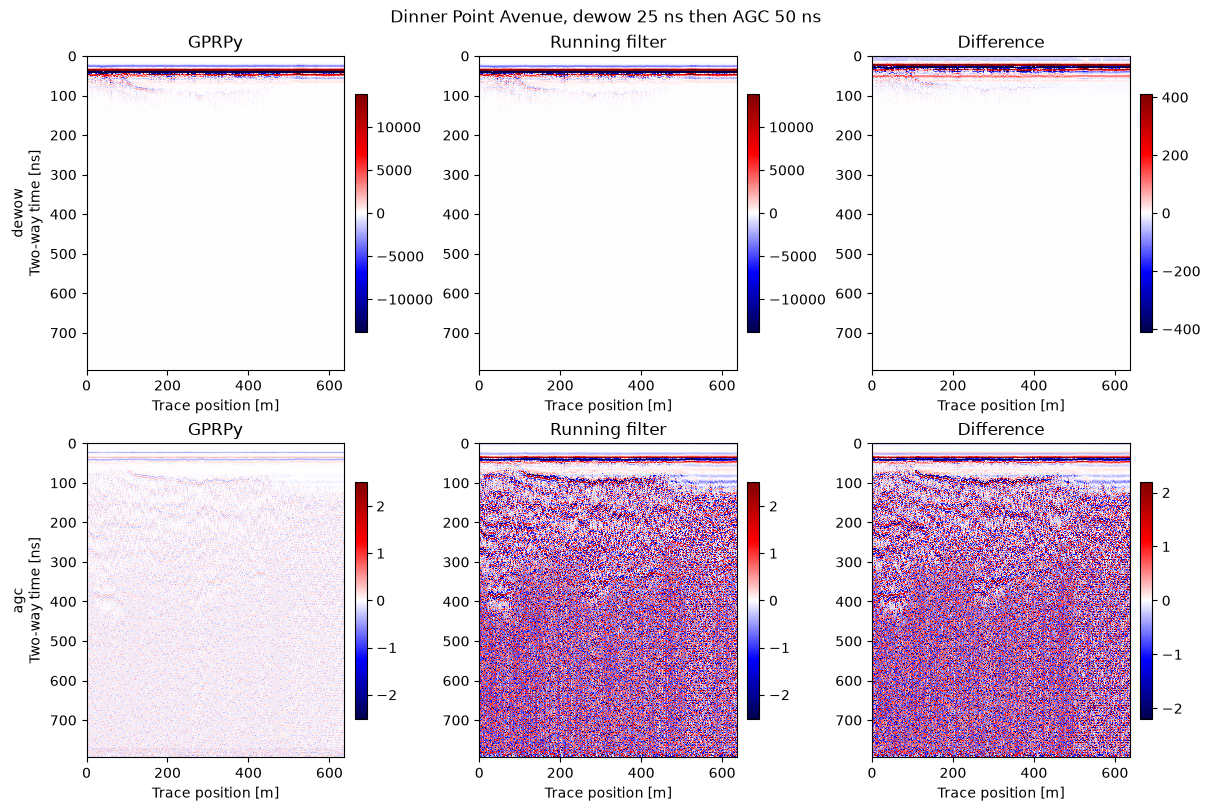

In [17]:
extent = [position_m[0], position_m[-1], time_ns[-1], time_ns[0]]
panels = {
    "dewow": (dewowed, mine_dewow, mine_dewow - dewowed),
    "agc": (gained, mine_agc, mine_agc - gained),
}

def colour_limit(*arrays):
    limit = max(float(np.percentile(np.abs(array), 99)) for array in arrays)
    return 1.0 if limit == 0 else limit

fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
for row, name in enumerate(("dewow", "agc")):
    reference, mine, difference = panels[name]
    shared = colour_limit(reference, mine)
    own = colour_limit(difference)
    limits = ((-shared, shared), (-shared, shared), (-own, own))
    titles = ("GPRPy", "Running filter", "Difference")
    for column, (data, (vmin, vmax), title) in enumerate(zip((reference, mine, difference), limits, titles)):
        image = axes[row, column].imshow(
            data,
            extent=extent,
            aspect="auto",
            cmap="seismic",
            vmin=vmin,
            vmax=vmax,
            interpolation="nearest",
        )
        axes[row, column].set_title(title)
        axes[row, column].set_xlabel("Trace position [m]")
        fig.colorbar(image, ax=axes[row, column], fraction=0.046, pad=0.04)
    axes[row, 0].set_ylabel(f"{name}\nTwo-way time [ns]")
fig.suptitle("Dinner Point Avenue, dewow 25 ns then AGC 50 ns")
